In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [2]:
os.getcwd()

'D:\\Projects\\СreditScoring\\notebooks'

## 0. Сбор данных
На выходе этого блока: Короткая витрина базовых факторов и широкая витрина со всеми поведенческими данными

In [3]:
train_df = pd.read_csv('../data/application_train.csv')
# поведенческие данные
"""previous_df = pd.read_csv('../input/competitions/home-credit-default-risk/previous_application.csv')
bureau_df = pd.read_csv('../input/competitions/home-credit-default-risk/bureau.csv')
bureau_balance = pd.read_csv('../input/competitions/home-credit-default-risk/bureau_balance.csv')
cash_df = pd.read_csv('../input/competitions/home-credit-default-risk/POS_CASH_balance.csv')
credit_card_df = pd.read_csv('../input/competitions/home-credit-default-risk/credit_card_balance.csv')
payments_df = pd.read_csv('../input/competitions/home-credit-default-risk/installments_payments.csv')
credit_card_df = pd.read_csv('../input/competitions/home-credit-default-risk/credit_card_balance.csv')
"""

train_df.head(5)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 1. Обработка данных
Базовый подход на исходной витрине.
1. проверка факторов на заполнение и пропуски -> выявить те, где пропуски несут смысловую нагрузку, а где - нет.
2. Проверка на нормальность распределения и выбросы. -> сгруппировать сильно перекошенные и несбалансированные факторы.
3. Проверка на корректность типов данных и корректность значений.
4. Исправление значений, нормализация.

In [4]:
factors = train_df.columns.tolist()
factors.remove('SK_ID_CURR')
factors.remove('TARGET')

In [5]:
train_df[factors].info()
df_stats = train_df[factors].describe()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 120 entries, NAME_CONTRACT_TYPE to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(39), str(16)
memory usage: 281.5 MB


In [6]:
print('Размер датасета:', train_df.shape)
n_entries = train_df.shape[0]
nan_factors = []
for factor in factors:
    missing = train_df[factor].isna().sum()
    if missing > 0:
        print("Пропуски по", factor, ' '*(30-len(factor)), f'{missing/n_entries:.2%}, {missing} набл.')
        nan_factors.append(factor)
print("Всего", len(nan_factors))

Размер датасета: (307511, 122)
Пропуски по AMT_ANNUITY                     0.00%, 12 набл.
Пропуски по AMT_GOODS_PRICE                 0.09%, 278 набл.
Пропуски по NAME_TYPE_SUITE                 0.42%, 1292 набл.
Пропуски по OWN_CAR_AGE                     65.99%, 202929 набл.
Пропуски по OCCUPATION_TYPE                 31.35%, 96391 набл.
Пропуски по CNT_FAM_MEMBERS                 0.00%, 2 набл.
Пропуски по EXT_SOURCE_1                    56.38%, 173378 набл.
Пропуски по EXT_SOURCE_2                    0.21%, 660 набл.
Пропуски по EXT_SOURCE_3                    19.83%, 60965 набл.
Пропуски по APARTMENTS_AVG                  50.75%, 156061 набл.
Пропуски по BASEMENTAREA_AVG                58.52%, 179943 набл.
Пропуски по YEARS_BEGINEXPLUATATION_AVG     48.78%, 150007 набл.
Пропуски по YEARS_BUILD_AVG                 66.50%, 204488 набл.
Пропуски по COMMONAREA_AVG                  69.87%, 214865 набл.
Пропуски по ELEVATORS_AVG                   53.30%, 163891 набл.
Пропуски по ENTRAN

Так как факторы с суффиксами _AVG, _MEDI, _MODE - агрегации, пропуски по ним не несут смысловой информации, это проблема качества данных и треует соотв. обработки.
Остаются факторы:

Из них:
- own_car_age сверить с FLAG_OWN_CAR, свести к одному фактору
- NAME_TYPE_SUITE - число пропусков невелико, можно списать в Unaccompanied
- 'AMT_ANNUITY','AMT_GOODS_PRICE' - также явные ошибки данных
- OCCUPATION_TYPE - можно трактовать как "не указан/скрыл"
- CNT_FAM_MEMBERS - можно трактовать как "не указан/скрыл"
- EXT_SOURCE_1...3 - скор внешнего источника. Трактовать отсутствие как смысловое значение некорректно. Возможно взять только (2),смотреть по корреляции с таргетом
- OBS_30_CNT_SOCIAL_CIRCLE доля пропусков незначительна: приравнять nan к нулю(?)
- AMT_REQ_CREDIT_BUREAU_HOUR - либо ошибка, либо отсутствие данных в бюро. вынести в отдельную категорию.
OBS_30_CNT_SOCIAL_CIRCLE        0.33%, 1021 набл.
- DEF_30_CNT_SOCIAL_CIRCLE        0.33%, 1021 набл.
- OBS_60_CNT_SOCIAL_CIRCLE        0.33%, 1021 набл.
- DEF_60_CNT_SOCIAL_CIRCLE        0.33%, 1021 набл.
- DAYS_LAST_PHONE_CHANGE          0.00%, 1 набл.
- AMT_REQ_CREDIT_BUREAU_HOUR      13.50%, 41519 набл.
- AMT_REQ_CREDIT_BUREAU_DAY       13.50%, 41519 набл.
- AMT_REQ_CREDIT_BUREAU_WEEK      13.50%, 41519 набл.
- AMT_REQ_CREDIT_BUREAU_MON       13.50%, 41519 набл.
- AMT_REQ_CREDIT_BUREAU_QRT       13.50%, 41519 набл.
- AMT_REQ_CREDIT_BUREAU_YEAR      13.50%, 41519 набл.

In [7]:
ess_nan_factors = ['AMT_ANNUITY','AMT_GOODS_PRICE','NAME_TYPE_SUITE',
                   'OWN_CAR_AGE','OCCUPATION_TYPE','CNT_FAM_MEMBERS',
                   'EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']


In [8]:
from pandas.api.types import is_numeric_dtype

bin_factors = []
cat_factors = []
num_factors = []
for factor in factors:
    if train_df[factor].nunique() <=2:
        bin_factors.append(factor)
    elif (train_df[factor].nunique() <=20)|(not is_numeric_dtype(train_df[factor])):
        cat_factors.append(factor)
    else:
        num_factors.append(factor)
print('Binnary factors number:', len(bin_factors))
print('Categorical factors number:', len(cat_factors))
print('Numerical factors number:', len(num_factors))


Binnary factors number: 36
Categorical factors number: 22
Numerical factors number: 62


In [9]:
train_df.ORGANIZATION_TYPE.nunique()

58

In [10]:
for factor in num_factors:
    print(train_df[factor].min())

25650.0
45000.0
1615.5
40500.0
0.00029
-25229
-17912
-24672.0
-7197
0.0
0
0.014568132412445587
8.173616518884397e-08
0.0005272652387098817
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
-4292.0
0.0
0.0


In [11]:
for factor in bin_factors:
    print(train_df[factor].min())

Cash loans
N
N
0
0
0
0
0
0
0
0
0
0
0
0
No
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0


In [13]:
# Задаем спецзначения: -999999 для числовых, -1 для бинарных, "-999999"
# на этапе биннинга исключаем из процесса. После биннинга добавляем в скоркарту с консервативным значением.

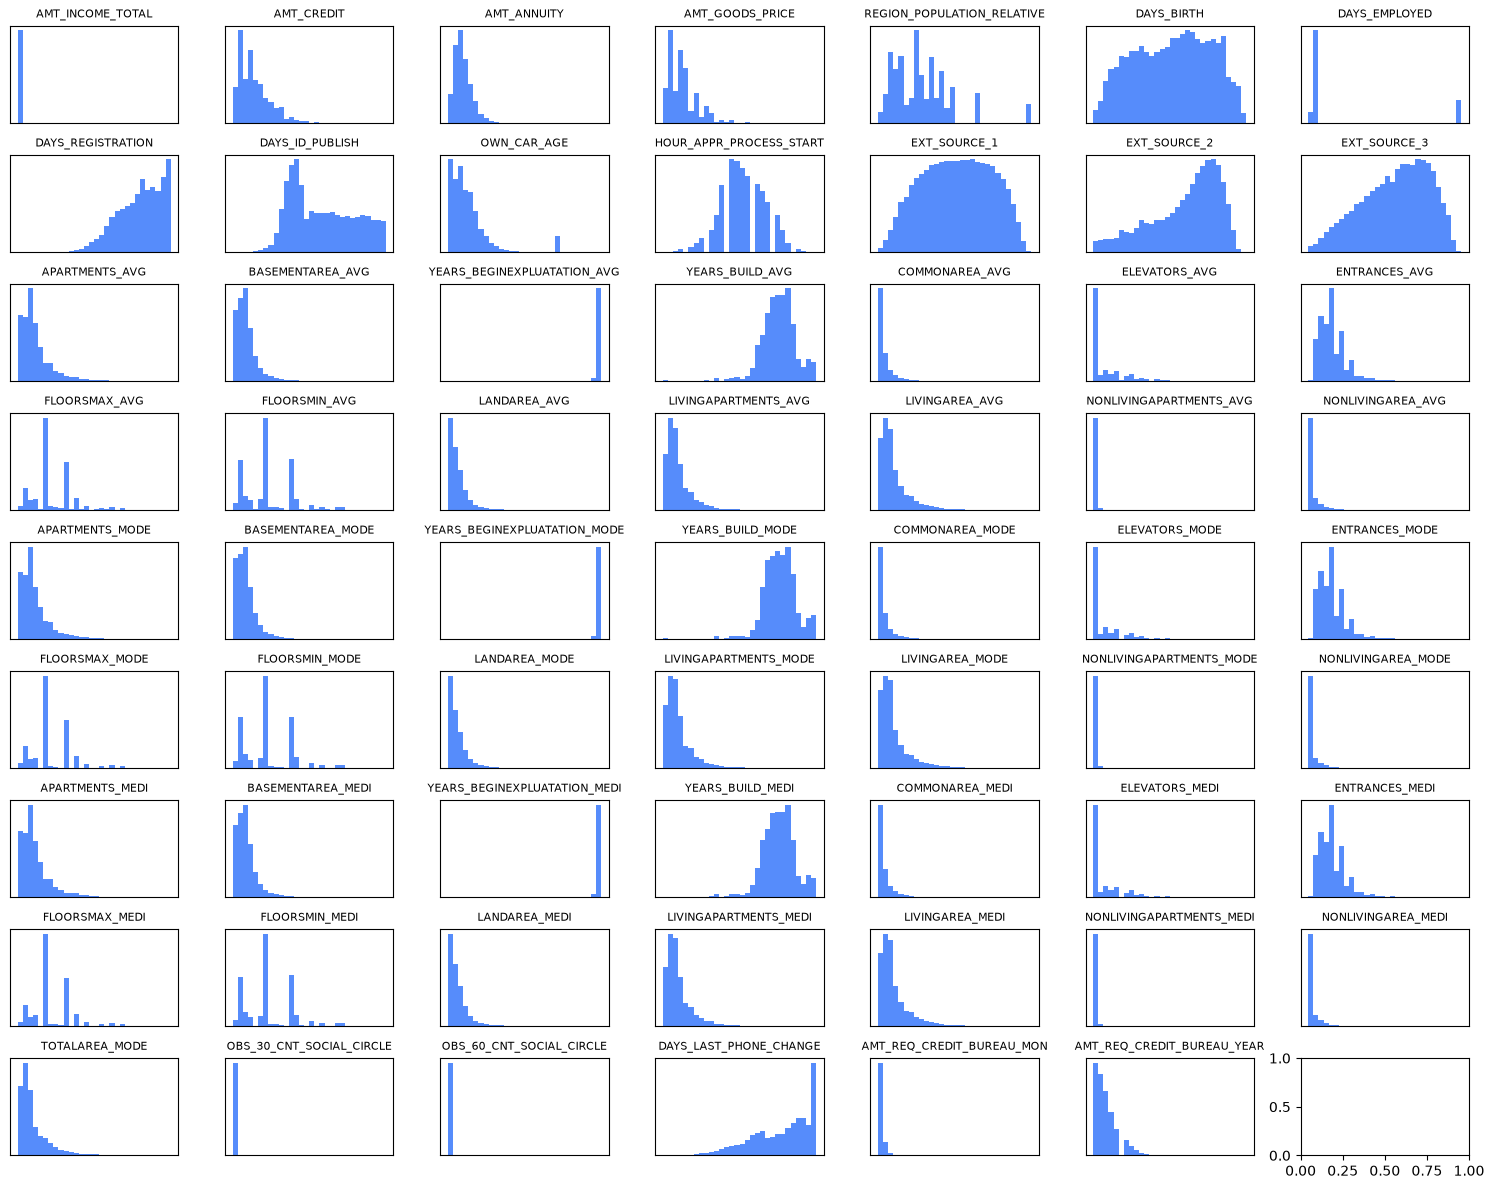

In [12]:
#графики распределений
# отдельно строим по факторам с более чем 2 значения
fig, axis = plt.subplots(9, 7, figsize = (15, 12))
for i, factor in enumerate(num_factors):
    axis[i//7, i%7].hist(train_df[factor].dropna(), bins=30)
    axis[i//7, i%7].set_title(factor, fontsize=8)
    axis[i//7, i%7].set_xticks([])
    axis[i//7, i%7].set_yticks([])
plt.tight_layout()
plt.show()

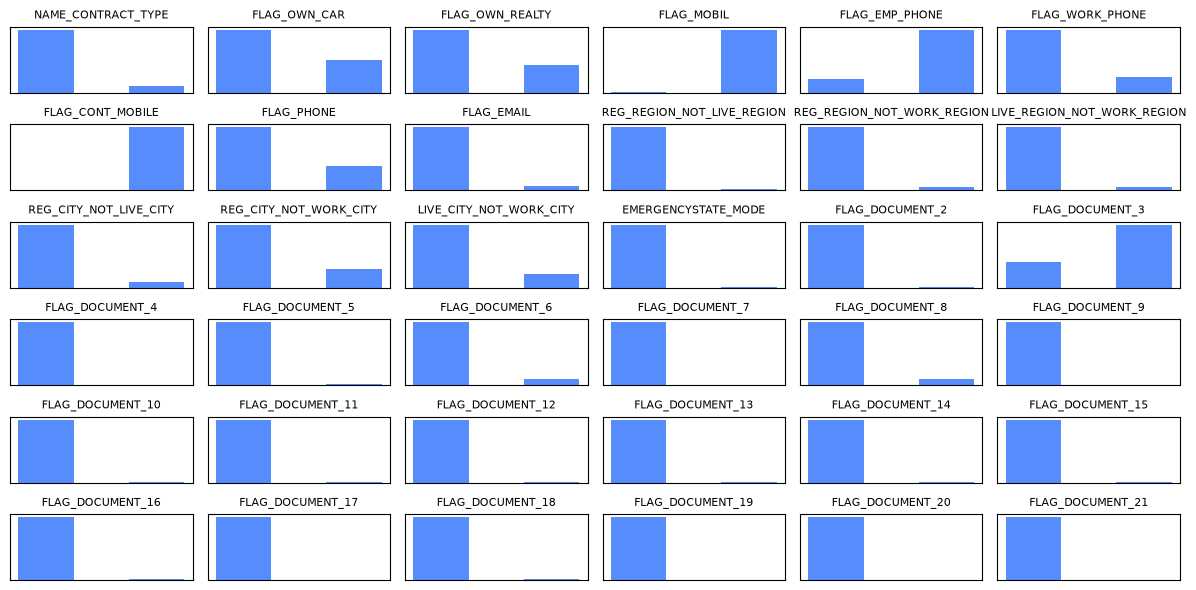

In [13]:
#графики распределений бинарны
fig, axis = plt.subplots(6, 6, figsize = (12, 6))
for i, factor in enumerate(bin_factors):
    axis[i//6, i%6].hist(train_df[factor].dropna(), bins=3)
    axis[i//6, i%6].set_title(factor, fontsize=8)
    axis[i//6, i%6].set_xticks([])
    axis[i//6, i%6].set_yticks([])
plt.tight_layout()
plt.show()

IndexError: index 3 is out of bounds for axis 0 with size 3

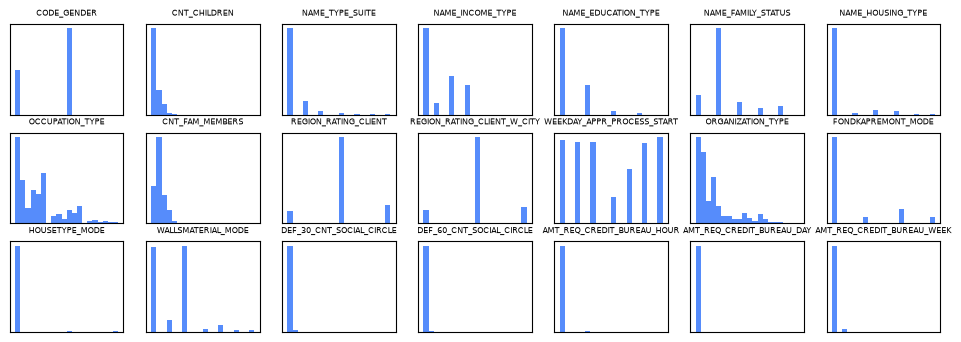

In [14]:
#графики распределений бинарных факторов
fig, axis = plt.subplots(3, 7, figsize = (12, 4))
for i, factor in enumerate(cat_factors):
    axis[i//7, i%7].hist(train_df[factor].dropna(), bins=20)
    axis[i//7, i%7].set_title(factor, fontsize=6)
    axis[i//7, i%7].set_xticks([])
    axis[i//7, i%7].set_yticks([])
plt.tight_layout()
plt.show()

In [15]:
import ipywidgets as widgets
def show_dist(factor, bins=30):
    plt.figure(figsize=(8, 4))
    plt.hist(train_df[factor].dropna(), bins=bins, edgecolor='white')
    plt.title(f'Распределение: {factor}')
    plt.xlabel(factor)
    plt.ylabel('Частота')
    plt.tight_layout()
    plt.show()

widgets.interact(
    show_dist,
    factor=widgets.Select(options=factors),
    bins=widgets.IntSlider(min=5, max=100, step=5, value=30),
)

interactive(children=(Select(description='factor', options=('NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR…

<function __main__.show_dist(factor, bins=30)>

## 3. Отбор факторов.


In [16]:
from sklearn.model_selection  import train_test_split
x_train, x_test, y_train, y_test = train_test_split(train_df[factors], train_df['TARGET'], test_size = 0.2, shuffle=True, random_state = 42)

In [17]:
x_train[num_factors].dtypes

AMT_INCOME_TOTAL              float64
AMT_CREDIT                    float64
AMT_ANNUITY                   float64
AMT_GOODS_PRICE               float64
REGION_POPULATION_RELATIVE    float64
                               ...   
OBS_30_CNT_SOCIAL_CIRCLE      float64
OBS_60_CNT_SOCIAL_CIRCLE      float64
DAYS_LAST_PHONE_CHANGE        float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 62, dtype: object

In [18]:
len(num_factors)

62

In [19]:
from sklearn.feature_selection import SelectKBest, f_classif, chi2, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  LabelEncoder()),
])
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler())
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe,     num_factors),
    #('cat', cat_pipe, cat_factors),
], remainder='drop')
pipe = Pipeline([
    ('prep',            preprocessor),
])
fit_pipe = pipe.fit(x_train[num_factors], y_train)

## 4. Однофакторный анализ
На данном этапе происходит отбор факторов и формирование списка переменных, которые позволяют ранжировать наблюдения по уровню риска.
Однофакторный анализ состоит:
1. Трансформации факторов с помощью WOE-преобразования (включает в себя поиск оптимального разбиения)
2. Оценка бизнес-логики фактора.
3. Оценка предиктивной способности фактора.

Переменные отсеивались, если не преодолевали порога Джини в 0.09.

1. Исследование факторов на корреляцию между собой.
2. Исследование на мультиколлинеарность.
3. Исследование на корреляцию с целевой переменной


In [24]:
shortlist = num_factors

In [26]:
from optbinning import OptimalBinning, BinningProcess, Scorecard

def bin_factor(X: pd.DataFrame, y:pd.Series, factor: str, max_n_bins: int=5, min_bin_size: float=0.05):
    """
    Обертка для OptimalBinning, для обработки пропусков (чтобы
    :param df:
    :param factor:
    :param max_n_bins:
    :param min_bin_size:
    :param nan_value:
    :return:
    """
    #add dtype?
    opt_binning = OptimalBinning(name=factor, min_bin_size=min_bin_size, max_n_bins=max_n_bins)
    mask = x_train[factor].notna()
    x_col = x_train.loc[mask, factor].values
    y_col = y_train.loc[mask].values
    opt_binning.fit(x_col, y_col)
    return opt_binning
binning_dict = {}
for factor in shortlist:
    binning_dict[factor] = bin_factor(x_train, y_train, factor)

In [27]:
binning_dict['EXT_SOURCE_1'].binning_table.build()

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.17)",6638,0.061758,5343,1295,0.195089,-1.090251,0.115759,0.013793
1,"[0.17, 0.28)",12008,0.111719,10463,1545,0.128664,-0.594706,0.050869,0.006267
2,"[0.28, 0.41)",20396,0.189758,18495,1901,0.093205,-0.232407,0.011315,0.001411
3,"[0.41, 0.69)",44651,0.415420,42023,2628,0.058856,0.264466,0.025986,0.003239
4,"[0.69, inf)",23791,0.221345,23063,728,0.030600,0.948156,0.134773,0.016243
5,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
6,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,107484,1.000000,99387,8097,0.075332,,0.338702,0.040953


In [28]:
np.unique(binning_dict['EXT_SOURCE_1'].transform(x_train['EXT_SOURCE_1'], metric_missing = 0), return_counts=True)

(array([-1.0902511 , -0.59470638, -0.23240734,  0.        ,  0.26446629,
         0.94815613]),
 array([  6638,  12008,  20396, 138524,  44651,  23791]))

In [29]:


#binning_process = BinningProcess(variable_names=shortlist, max_n_bins=5,min_bin_size=0.05)
#binning_process.fit_transform(x_train[shortlist], y_train, metric_missing = 0)

In [37]:
#binning_process.get_binned_variable('EXT_SOURCE_1').binning_table.build(add_totals=False)

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.28)",18646,0.075794,15806,2840,0.152311,-0.715020,0.052188,0.006388
1,"[0.28, 0.41)",20396,0.082908,18495,1901,0.093205,-0.156486,0.002168,0.000271
2,"[0.41, 0.57)",24164,0.098224,22556,1608,0.066545,0.209404,0.003946,0.000492
3,"[0.57, 0.69)",20487,0.083278,19467,1020,0.049788,0.517312,0.017986,0.002224
4,"[0.69, inf)",23791,0.096708,23063,728,0.030600,1.024078,0.066936,0.008020
5,Special,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000
6,Missing,138524,0.563087,126745,11779,0.085032,-0.055747,0.001791,0.000224


In [30]:
from matplotlib.ticker import PercentFormatter
# ----------------------------------------------------------------------
# 2. График для одной переменной
# ----------------------------------------------------------------------
def plot_monotonicity_single(
    binning_process,
    variable,
    ax=None,
    bar_color="#5BA3E0",        # голубой — Count
    line_color="#D9534F",       # красный — Event rate
    special_bar_color="#B0B0B0",
    show_woe=False,
    annotate_counts=True,
    rotate_labels=45,
    figsize=(9, 4.5),
):
    """Строит график: столбцы = Count, линия = Event rate."""
    table = binning_process.get_binned_variable(variable).binning_table.build(add_totals=False)
    table = table[~table["Bin"].isin(["Special", "Missing"])]

    labels = table["Bin"].astype(str).tolist()
    counts = table["Count"].to_numpy(dtype=float)
    event_rate = pd.to_numeric(table["Event rate"], errors="coerce").to_numpy(dtype=float)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    x = np.arange(len(table))

    # --- Столбцы: Count ---
    bars = ax.bar(x, counts, color=bar_color, edgecolor="white", width=0.75, label="Count")
    ax.set_ylabel("Count", color="#333333")
    ax.set_xlabel("Бин")

    # Подписи по оси X (обрезаем длинные интервалы)
    short = [lbl if len(lbl) <= 20 else lbl[:19] + "…" for lbl in labels]
    ax.set_xticks(x)
    ax.set_xticklabels(short, rotation=rotate_labels, ha="right", fontsize=8)


    # --- Линия: Event rate (только по регулярным бинам) ---
    ax2 = ax.twinx()
    line_data = event_rate.copy()
    ax2.plot(x, line_data, color=line_color, marker="o",
             linewidth=2, markersize=6, label="Event rate")


    ax2.set_ylabel("Event rate", color=line_color)
    ax2.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=1))
    ax2.tick_params(axis="y", colors=line_color)

    # Разумный диапазон для event rate
    ax2.set_ylim(0, max(0.05, event_rate.max() * 1.2))
    ax.set_title(f"{variable}",
                 fontsize=11, fontweight="bold")
    ax.legend(loc="upper left", fontsize=8, framealpha=0.9)
    ax.grid(axis="y", alpha=0.3)
    return fig, (ax, ax2)
#plot_monotonicity_single(binning_process, variable="AMT_CREDIT")

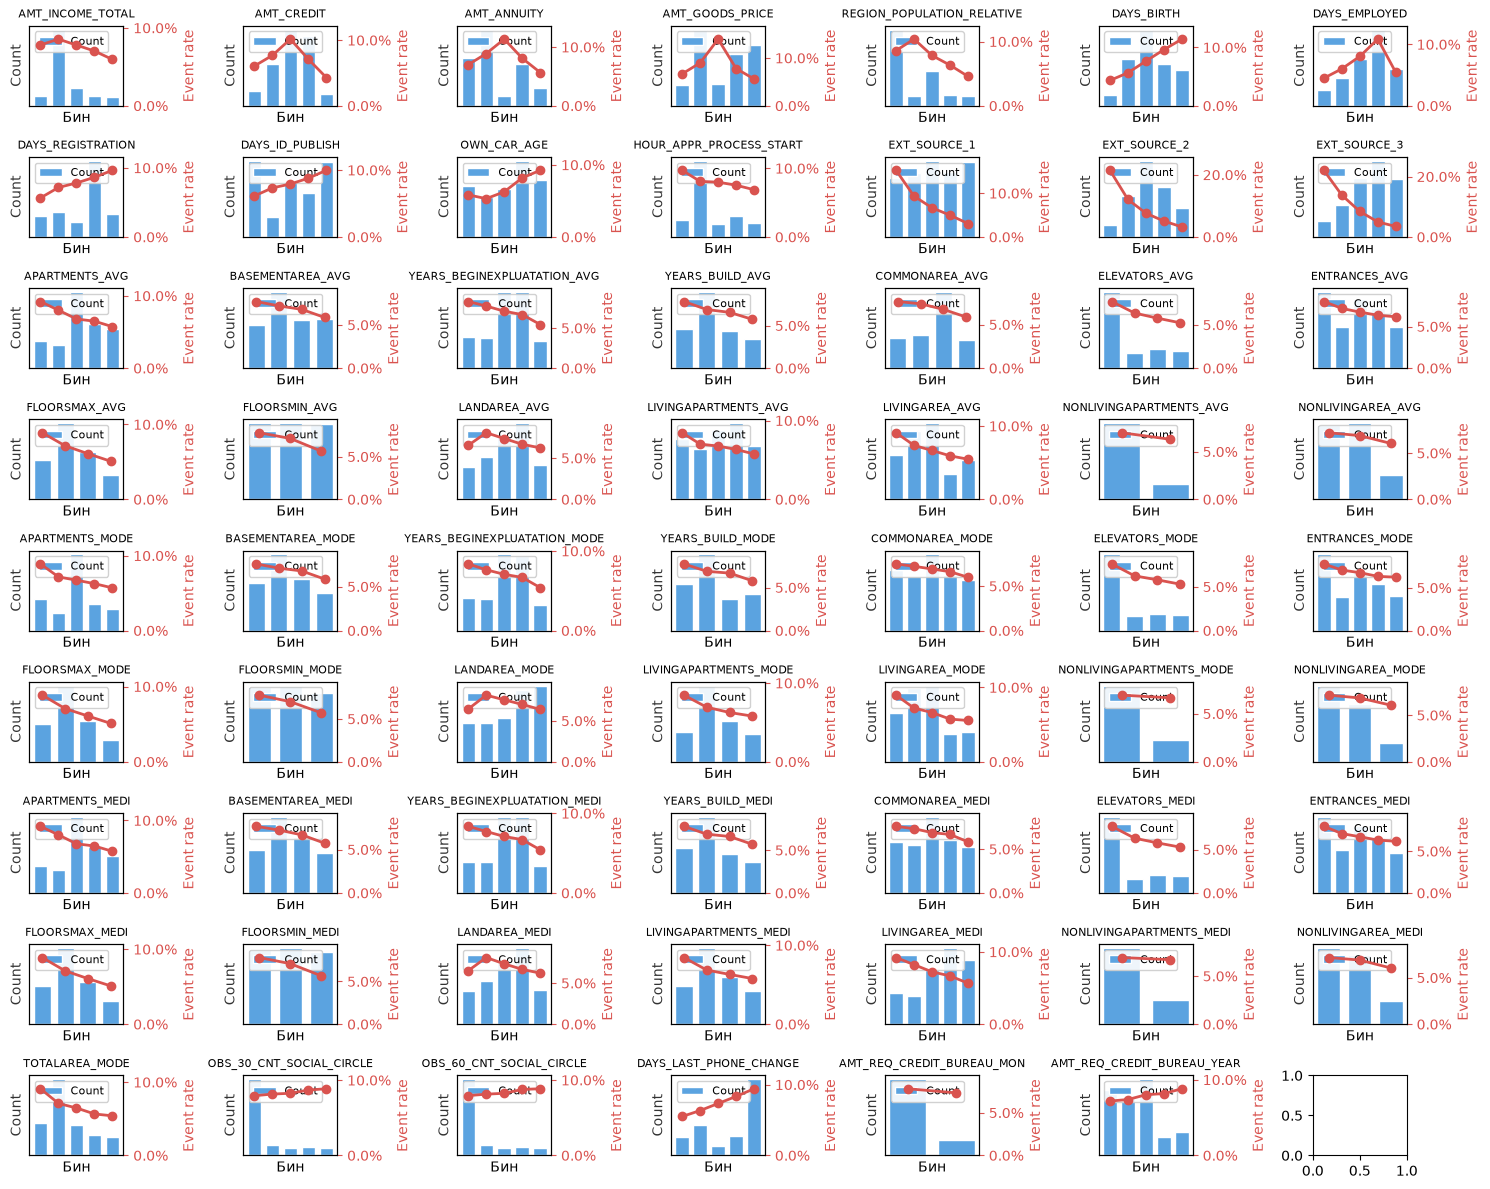

In [28]:
fig, axis = plt.subplots(9, 7, figsize=(15, 12))
for i, factor in enumerate(num_factors):
    plot_monotonicity_single(binning_process, variable=factor, ax=axis[i // 7, i % 7])
    axis[i // 7, i % 7].set_title(factor, fontsize=8)
    axis[i // 7, i % 7].set_xticks([])
    axis[i // 7, i % 7].set_yticks([])
plt.tight_layout()
plt.show()

In [29]:
summary = binning_process.summary()
summary.to_excel('./scorecards/scorecard_long.xlsx')

## 5. Обучение логистической регрессии

In [49]:
sh_list = ['EXT_SOURCE_3',
'EXT_SOURCE_2',
'DAYS_EMPLOYED',
'EXT_SOURCE_1',
'DAYS_BIRTH',
'AMT_GOODS_PRICE',
'ORGANIZATION_TYPE',
'AMT_CREDIT',
'DAYS_ID_PUBLISH',
'DAYS_LAST_PHONE_CHANGE',
'FLOORSMAX_AVG',
'TOTALAREA_MODE',
'FLOORSMAX_MEDI',
'FLOORSMAX_MODE',
'LIVINGAREA_MEDI',
'LIVINGAREA_AVG',
'APARTMENTS_AVG',
'APARTMENTS_MEDI',
'AMT_ANNUITY']


In [52]:
estimator = LogisticRegression(
    solver="lbfgs",
    C=1.0,
    max_iter=1000,
)
sh_list = list(binning_dict.keys())

binning_process.fit_from_dict(binning_dict)
estimator.fit(binning_process.transform(x_train[sh_list], metric_missing=0), y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [68]:
coef_dict = {}
for idx, factor in enumerate(estimator.feature_names_in_):
    coef_dict[factor] = float(estimator.coef_[0,idx])
coef_dict

{'AMT_INCOME_TOTAL': -0.026822024353202086,
 'AMT_CREDIT': 0.0017987412062783223,
 'AMT_ANNUITY': -0.6012899672478592,
 'AMT_GOODS_PRICE': -0.5531434774103854,
 'REGION_POPULATION_RELATIVE': -0.23844061085497945,
 'DAYS_BIRTH': 0.13330922180006566,
 'DAYS_EMPLOYED': -0.5051856981207962,
 'DAYS_REGISTRATION': -0.3073372465201074,
 'DAYS_ID_PUBLISH': -0.3154920122129784,
 'OWN_CAR_AGE': -0.6062648033417852,
 'HOUR_APPR_PROCESS_START': -0.26993863309869354,
 'EXT_SOURCE_1': -0.5580296697466448,
 'EXT_SOURCE_2': -0.7833835749773709,
 'EXT_SOURCE_3': -0.8114388315810697,
 'APARTMENTS_AVG': -0.042056977272652,
 'BASEMENTAREA_AVG': 0.0339504549097705,
 'YEARS_BEGINEXPLUATATION_AVG': -0.13555495512783444,
 'YEARS_BUILD_AVG': -0.036982940690302724,
 'COMMONAREA_AVG': -0.08855627203870045,
 'ELEVATORS_AVG': 0.029730336180426573,
 'ENTRANCES_AVG': -0.08465715206579638,
 'FLOORSMAX_AVG': -0.09221522645345168,
 'FLOORSMIN_AVG': -0.02858405904240183,
 'LANDAREA_AVG': -0.0020099957892010735,
 'LIVING

In [72]:
#build scorecard
factor = 'EXT_SOURCE_1'
def prep_scorecard_table(x_df: pd.DataFrame, y: pd.Series,  binning_dict:dict, factor: str):
    table = binning_dict[factor].binning_table.build(add_totals=False).set_index('Bin')
    table.loc['Missing', 'Count'] = x_df[factor].isna().sum()
    table.loc['Missing', 'Count (%)'] = x_df[factor].isna().mean()
    mask = x_df[factor].notna()
    x_col = x_df.loc[mask, factor].values
    y_col = y.loc[mask].values
    table.loc['Missing', 'Non-event'] = y_col.shape - y_col.sum()
    table.loc['Missing', 'Event'] = y_col.sum()
    table.loc['Missing', 'Event rate'] = y_col.sum()/y_col.shape
    table['Coefficient'] = coef_dict[factor]
    table['Score'] = table['Coefficient']*table['WoE']
    return table
prep_scorecard_table(x_df=x_train, y=y_train, binning_dict=binning_dict, factor='EXT_SOURCE_1')

,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS,Coefficient,Score
Bin,,,,,,,,,,
"(-inf, 0.17)",6638,0.061758,5343,1295,0.195089,-1.090251,0.115759,0.013793,-0.55803,0.608392
"[0.17, 0.28)",12008,0.111719,10463,1545,0.128664,-0.594706,0.050869,0.006267,-0.55803,0.331864
"[0.28, 0.41)",20396,0.189758,18495,1901,0.093205,-0.232407,0.011315,0.001411,-0.55803,0.129690
"[0.41, 0.69)",44651,0.415420,42023,2628,0.058856,0.264466,0.025986,0.003239,-0.55803,-0.147580
"[0.69, inf)",23791,0.221345,23063,728,0.030600,0.948156,0.134773,0.016243,-0.55803,-0.529099
Special,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000,-0.55803,-0.000000
Missing,138524,0.563087,99387,8097,0.075332,0.000000,0.000000,0.000000,-0.55803,-0.000000


In [47]:
estimator = LogisticRegression(
    solver="lbfgs",
    C=1.0,
    max_iter=1000,
)
sh_list = list(binning_dict.keys())
binning_process = BinningProcess(variable_names=sh_list)

# 2. Fit the binning process from the dictionary of fitted OptimalBinning objects
binning_process.fit_from_dict(binning_dict)

scorecard = Scorecard(
    binning_process=binning_process,
    estimator=estimator,
    scaling_method="pdo_odds",          # or "min_max"
    scaling_method_params={
        "pdo": 20,                      # points to double the odds
        "odds": 50,                     # odds at the reference score
        "scorecard_points": 600,        # reference score
    },
    reverse_scorecard=False,            # set True if higher score = higher risk
    rounding=True,                      # round points to integers
    verbose=False,
)

scorecard.fit(x_train[sh_list], y_train, metric_missing=0)

,binning_process,"BinningProces...A_MODE', ...])"
,estimator,LogisticRegre...max_iter=1000)
,scaling_method,'pdo_odds'
,scaling_method_params,"{'odds': 50, 'pdo': 20, 'scorecard_points': 600}"
,rounding,True
,intercept_based,False
,reverse_scorecard,False
,verbose,False
Name,Type,Value
binning_process_,BinningProcess,"BinningProces...A_MODE', ...])"
estimator_,LogisticRegression,LogisticRegre...max_iter=1000)


In [44]:
binning_process.binning_transform_params.get()

AttributeError: 'NoneType' object has no attribute 'get'

In [39]:
binning_process.get_binned_variable('EXT_SOURCE_1').binning_table.build(add_totals=False)

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.17)",6638,0.061758,5343,1295,0.195089,-1.090251,0.115759,0.013793
1,"[0.17, 0.28)",12008,0.111719,10463,1545,0.128664,-0.594706,0.050869,0.006267
2,"[0.28, 0.41)",20396,0.189758,18495,1901,0.093205,-0.232407,0.011315,0.001411
3,"[0.41, 0.69)",44651,0.415420,42023,2628,0.058856,0.264466,0.025986,0.003239
4,"[0.69, inf)",23791,0.221345,23063,728,0.030600,0.948156,0.134773,0.016243
5,Special,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000
6,Missing,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000


In [40]:
binning_process.get_binned_variable('AMT_REQ_CREDIT_BUREAU_YEAR').binning_table.build(add_totals=False)

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.50)",57459,0.270018,53332,4127,0.071825,0.079494,0.001650,0.000206
1,"[0.50, 1.50)",50661,0.238072,46921,3740,0.073824,0.049888,0.000580,0.000073
2,"[1.50, 3.50)",67066,0.315164,61690,5376,0.080160,-0.039315,0.000495,0.000062
3,"[3.50, 5.50)",26220,0.123216,24057,2163,0.082494,-0.070562,0.000632,0.000079
4,"[5.50, inf)",11391,0.053530,10346,1045,0.091739,-0.186909,0.002024,0.000253
5,Special,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000
6,Missing,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000


In [48]:
scorecard_table_summary = scorecard.table(style="detailed")
scorecard_table_summary


,Variable,Bin id,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS,Coefficient,Points
0,AMT_INCOME_TOTAL,0,"(-inf, 76477.50)",19083,0.077571,17592,1491,0.078132,0.036391,0.000101,0.000013,0.062649,9.0
1,AMT_INCOME_TOTAL,1,"[76477.50, 98977.50)",28931,0.117602,26505,2426,0.083855,-0.040516,0.000196,0.000025,0.062649,9.0
2,AMT_INCOME_TOTAL,2,"[98977.50, 139484.25)",71608,0.291080,65477,6131,0.085619,-0.063265,0.001196,0.000150,0.062649,9.0
3,AMT_INCOME_TOTAL,3,"[139484.25, 160814.25)",26880,0.109265,24502,2378,0.088467,-0.099111,0.001119,0.000140,0.062649,9.0
4,AMT_INCOME_TOTAL,4,"[160814.25, 185517.00)",26400,0.107314,24168,2232,0.084545,-0.049475,0.000268,0.000034,0.062649,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2,AMT_REQ_CREDIT_BUREAU_YEAR,2,"[1.50, 3.50)",67066,0.272617,61690,5376,0.080160,0.008571,0.000020,0.000002,-0.485487,9.0
3,AMT_REQ_CREDIT_BUREAU_YEAR,3,"[3.50, 4.50)",16600,0.067477,15243,1357,0.081747,-0.012762,0.000011,0.000001,-0.485487,9.0
4,AMT_REQ_CREDIT_BUREAU_YEAR,4,"[4.50, inf)",21011,0.085408,19160,1851,0.088097,-0.094507,0.000794,0.000099,-0.485487,8.0
5,AMT_REQ_CREDIT_BUREAU_YEAR,5,Special,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000,-0.485487,9.0


## 6. Калибровка

In [ ]:
raw_scores = scorecard.score(train_df[shortlist])


In [ ]:
raw_scores.shape

In [ ]:

# Обучаем логистическую регрессию для калибровки
calibrator = LogisticRegression()
calibrator.fit(raw_scores.reshape(-1, 1), train_df['TARGET'])


## 7. Тестирование результата и коммит.

H0 - гипотеза - все нули. Используем как baseline вариант для оценки прогресса.

In [ ]:
val_df = pd.read_csv('../data/application_test.csv')
ids = val_df.pop('SK_ID_CURR')

probs = [0]*len(ids)

output = pd.DataFrame({'SK_ID_CURR': ids,
                       'TARGET': probs})
output.to_csv('./submits/submission_0.csv', index=False)

In [ ]:
# Получаем откалиброванные вероятности для тестовой выборки
raw_test = scorecard.score(val_df[shortlist])
calibrated_probs = calibrator.predict_proba(raw_test.reshape(-1, 1))[:,1]

output = pd.DataFrame({'SK_ID_CURR': ids,
                       'TARGET': calibrated_probs})
output.to_csv('./submits/submission_1.csv', index=False)
